# 음성 모델 수업 복습과 다음 단계
## 1 ~ 4일차 핵심 정리 · 5 ~ 6일차 학습 안내

지금까지 우리는 **사람이 듣는 소리를 컴퓨터가 다룰 수 있는 숫자로 바꾸는 과정**을 배웠습니다.

오늘은 그 과정을 처음부터 한 번에 다시 따라가 보고, 5~6일차에 무엇을 배우는지 미리 살펴봅니다.

**소리 → 디지털 파형 → 시간·주파수 분석 → Log-Mel 특징 → 입력·정답 준비 → 모델 구조 이해**

| 순서 | 내용 | 시간 |
|---|---|---:|
| 1 | 1일차 · 소리는 어떻게 숫자가 될까요? | 3분 |
| 2 | 2일차 · 처리 조건 맞추기 | 4분 |
| 3 | 3일차 · 어떤 주파수가 언제 나타날까요? | 4분 |
| 4 | 4일차 · Mel과 Log-Mel | 4분 |
| 5 | 한눈에 보기 + 5~6일차 안내 | 5분 |

코드는 짧게 실행만 하면서 결과를 확인합니다. 셀 아래쪽의 `assert` 줄은 결과가 맞는지 자동으로 확인하는 줄입니다. 아무 메시지 없이 지나가면 정상입니다.

In [1]:
# 준비: 계산용 numpy, 그림용 matplotlib, 리샘플링용 scipy
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import resample_poly

# 그림에 한글이 깨지지 않도록 운영체제에 있는 한글 폰트를 찾아 설정합니다.
from matplotlib import font_manager
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(name == f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False   # 음수 부호(-)가 깨지는 것 방지

print("준비 완료")

준비 완료


---
## 1일차 · 소리는 어떻게 숫자가 될까요?

마이크는 공기의 떨림을 전기 신호로 바꾸고, 컴퓨터는 그 신호를 **일정한 시간 간격으로 재서** 숫자로 저장합니다.

비유하면, 움직이는 그네를 사진으로 연속 촬영하는 것과 같습니다. 사진 한 장이 **샘플** 하나이고, 1초에 몇 장 찍는지가 **샘플링 레이트**입니다.

| 용어 | 뜻 | 예시 |
|---|---|---|
| 샘플 | 어느 한 순간에 잰 파형의 값 | 0.2, -0.3 (음수도 정상입니다) |
| 샘플링 레이트 | 1초에 몇 번 재는가 | 16,000Hz = 1초에 16,000번 |
| 소리의 주파수 | 소리가 1초에 몇 번 떨리는가 | 440Hz = 1초에 440번 떨림 |

마지막 두 줄이 헷갈리기 쉽습니다. **주파수는 소리의 성질**이고, **샘플링 레이트는 녹음하는 방식**입니다.

녹음 시간은 간단히 구할 수 있습니다. **녹음 시간 = 샘플 수 ÷ 샘플링 레이트**

In [2]:
sr = 16000                                  # 샘플링 레이트: 1초에 16,000번 측정
t = np.arange(2 * sr) / sr                  # 2초 동안 각 샘플을 잰 시각
audio = 0.5 * np.sin(2 * np.pi * 440 * t)   # 440Hz로 떨리는 소리

print("샘플 수:", len(audio))
print("녹음 시간:", len(audio) / sr, "초")
print("처음 5개 샘플:", np.round(audio[:5], 3))

assert len(audio) == 32000          # 16,000 x 2초
assert len(audio) / sr == 2.0

샘플 수: 32000
녹음 시간: 2.0 초
처음 5개 샘플: [0.    0.086 0.169 0.248 0.319]


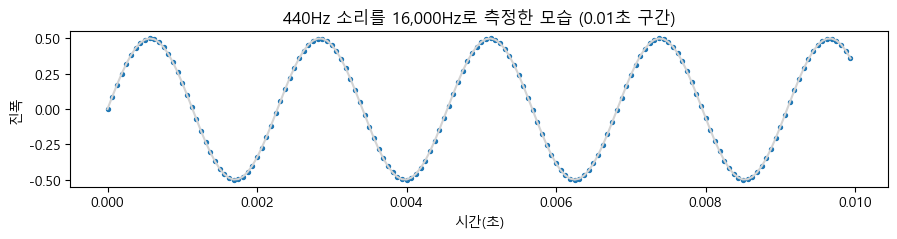

In [3]:
# 처음 0.01초(160개 샘플)만 확대해서 보면, 점 하나하나가 샘플입니다.
n = 160
plt.figure(figsize=(9, 2.5))
plt.plot(t[:n], audio[:n], color="lightgray")
plt.scatter(t[:n], audio[:n], s=8)
plt.title("440Hz 소리를 16,000Hz로 측정한 모습 (0.01초 구간)")
plt.xlabel("시간(초)"); plt.ylabel("진폭")
plt.tight_layout(); plt.show()

**1일차 핵심:** 음성 파일 안에는 **시간 순서대로 잰 파형의 숫자**가 들어 있습니다.

---
## 2일차 · 음성 파일의 처리 조건을 맞춥니다

같은 "음성 파일"이라도 조건이 제각각입니다. 어떤 파일은 48,000Hz 스테레오이고, 어떤 파일은 16,000Hz 모노입니다.

모델은 정해진 조건의 입력만 받기 때문에, 먼저 조건을 통일합니다.

| 작업 | 하는 일 | 바뀌지 않아야 하는 것 |
|---|---|---|
| 모노 변환 | 왼쪽·오른쪽 채널을 하나로 합치기 | 녹음 시간 |
| 리샘플링 | 다른 측정 간격에 맞춰 값을 다시 계산 | 녹음 시간, 말의 내용, 음높이 |
| 구간 자르기 | 원하는 시간만큼 잘라내기 | 현재 샘플링 레이트 기준으로 위치 계산 |

아래에서 48,000Hz 스테레오 2초짜리 음성을 16,000Hz 모노로 바꿔 봅니다.

In [4]:
# 48,000Hz 스테레오 2초짜리 음성을 만들어 봅니다. (왼쪽/오른쪽 크기만 조금 다름)
sr_orig = 48000
t48 = np.arange(2 * sr_orig) / sr_orig
left  = 0.6 * np.sin(2 * np.pi * 440 * t48)
right = 0.4 * np.sin(2 * np.pi * 440 * t48)
stereo = np.stack([left, right], axis=1)     # 모양: (샘플 수, 채널 수)
print("원본 모양:", stereo.shape, "→", len(stereo) / sr_orig, "초")

# 1) 모노 변환: 두 채널의 평균
mono = stereo.mean(axis=1)
print("모노 모양:", mono.shape, "→", len(mono) / sr_orig, "초")

# 2) 리샘플링: 48,000 → 16,000 (샘플 수가 1/3로 줄어듦)
sr_new = 16000
mono16 = resample_poly(mono, up=1, down=3)
print("리샘플링 후:", mono16.shape, "→", len(mono16) / sr_new, "초")

assert len(mono) / sr_orig == 2.0       # 모노 변환은 시간을 줄이지 않습니다
assert len(mono16) == 32000             # 16,000 x 2초
assert len(mono16) / sr_new == 2.0      # 리샘플링 후에도 2초 그대로

원본 모양: (96000, 2) → 2.0 초
모노 모양: (96000,) → 2.0 초
리샘플링 후: (32000,) → 2.0 초


### 자주 하는 실수: 숫자만 바꾸기

배열은 그대로 두고 `sr = 16000`처럼 **변수만** 바꾸면 어떻게 될까요?

컴퓨터는 96,000개 샘플을 "1초에 16,000개씩" 재생하므로 6초짜리 소리로 받아들입니다. 소리가 3배 느리고 낮게 들립니다.

In [5]:
wrong_sec = len(mono) / 16000      # 배열은 48kHz 그대로인데 기준만 16kHz로 착각
right_sec = len(mono16) / 16000    # 제대로 리샘플링한 결과

print("변수만 바꾼 경우:", wrong_sec, "초")
print("제대로 리샘플링:", right_sec, "초")

assert wrong_sec == 6.0 and right_sec == 2.0

변수만 바꾼 경우: 6.0 초
제대로 리샘플링: 2.0 초


In [6]:
# 3) 구간 자르기: 0.5초 ~ 1.5초
#    샘플 위치 = 시간 x '현재' 샘플링 레이트 (지금은 16,000)
start = int(0.5 * sr_new)
end   = int(1.5 * sr_new)
clip = mono16[start:end]

print("자른 위치:", start, "~", end)
print("자른 길이:", len(clip) / sr_new, "초")

assert start == 8000 and end == 24000
assert len(clip) / sr_new == 1.0

자른 위치: 8000 ~ 24000
자른 길이: 1.0 초


**2일차 핵심:** 말의 내용과 시간은 그대로 두고, **채널 수와 샘플링 레이트를 모델이 원하는 조건으로 맞춥니다.**

---
## 3일차 · 어떤 주파수가 언제 나타날까요?

파형은 "시간에 따라 진폭이 어떻게 변하는가"를 보여 줍니다. 하지만 여러 소리가 섞이면 파형만 보고 어떤 높이의 소리가 들어 있는지 알기 어렵습니다.

- **FFT**: 어떤 구간 안에 **어떤 주파수가 얼마나** 들어 있는지 알려 줍니다. 합창을 듣고 "소프라노와 베이스가 있다"고 알아내는 것과 비슷합니다.
- **STFT**: 음성을 짧게 잘라 FFT를 반복합니다. "소프라노가 **언제** 나오고, 베이스가 **언제** 나오는가"까지 알 수 있습니다.

아래 소리는 **앞 1초는 440Hz, 뒤 1초는 880Hz**입니다.

In [7]:
sr = 16000
t1 = np.arange(sr) / sr
signal = np.concatenate([np.sin(2 * np.pi * 440 * t1),     # 앞 1초: 440Hz
                         np.sin(2 * np.pi * 880 * t1)])    # 뒤 1초: 880Hz

# 전체 구간에 FFT 한 번
spectrum = np.abs(np.fft.rfft(signal))                 # 주파수별 크기
freqs = np.fft.rfftfreq(len(signal), d=1/sr)           # 각 칸이 몇 Hz인지

top2 = np.sort(freqs[np.argsort(spectrum)[-2:]])       # 가장 큰 두 주파수
print("FFT로 찾은 주파수:", top2, "Hz")
print("하지만 '언제' 나왔는지는 이 결과만으로 알 수 없습니다.")

assert list(top2) == [440.0, 880.0]

FFT로 찾은 주파수: [440. 880.] Hz
하지만 '언제' 나왔는지는 이 결과만으로 알 수 없습니다.


### STFT: 짧은 창을 옮겨 가며 FFT

| 용어 | 뜻 | 이번 예시 |
|---|---|---|
| 프레임 | 한 번에 분석하는 짧은 구간 | 512샘플 (0.032초) |
| 이동 간격 | 다음 프레임까지 옮기는 거리 | 128샘플 |

프레임이 512이고 이동이 128이면, 프레임끼리 서로 겹치면서 촘촘하게 분석합니다.

In [8]:
frame_len, hop = 512, 128

# 신호를 512개씩 잘라 128칸씩 옮기며 프레임을 만듭니다 (가장자리 패딩 없음)
n_frames = 1 + (len(signal) - frame_len) // hop
frames = np.stack([signal[i*hop : i*hop + frame_len] for i in range(n_frames)])

# 각 프레임에 창(window)을 곱한 뒤 FFT → 크기
window = np.hanning(frame_len)
stft_mag = np.abs(np.fft.rfft(frames * window, axis=1))   # 모양: (시간, 주파수)

print("프레임 개수:", n_frames)
print("STFT 크기 모양:", stft_mag.shape, "= (시간 프레임, 주파수 칸)")

assert stft_mag.shape == (247, 257)

프레임 개수: 247
STFT 크기 모양: (247, 257) = (시간 프레임, 주파수 칸)


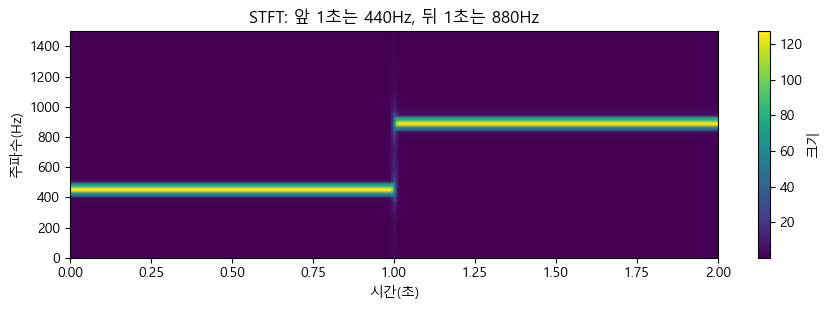

In [9]:
plt.figure(figsize=(9, 3.2))
plt.imshow(stft_mag.T, origin="lower", aspect="auto",
           extent=[0, len(signal)/sr, 0, sr/2])
plt.ylim(0, 1500)
plt.title("STFT: 앞 1초는 440Hz, 뒤 1초는 880Hz")
plt.xlabel("시간(초)"); plt.ylabel("주파수(Hz)")
plt.colorbar(label="크기")
plt.tight_layout(); plt.show()

가로축은 시간, 세로축은 주파수, 색은 크기입니다. 1초를 지나면서 밝은 선이 위로 올라가는 것이 보입니다.

**3일차 핵심:** "어떤 주파수가 **있는가**?"에서 "어떤 주파수가 **언제** 나타나는가?"로 분석을 넓혔습니다.

---
## 4일차 · Mel과 Log-Mel로 정리합니다

STFT 결과를 그대로 쓰기에는 주파수 칸이 너무 많고(257개), 값의 차이도 너무 큽니다. 그래서 세 단계로 정리합니다.

| 단계 | 하는 일 | 비유 |
|---|---|---|
| ① 파워 | 크기를 제곱 | 크기 2 → 파워 4, 크기 3 → 파워 9 |
| ② Mel 필터 | 주변 주파수 칸들을 가중치를 주어 묶기 | 257칸짜리 자를 사람 귀에 맞춘 40칸짜리 자로 바꾸기 |
| ③ 로그 | 아주 큰 값과 아주 작은 값의 차이를 줄이기 | 1, 10, 100, 1000 → 0, 1, 2, 3 |

사람 귀는 낮은 소리의 차이는 잘 구분하지만, 높은 소리의 차이는 덜 민감합니다. 그래서 Mel 필터는 **낮은 쪽은 촘촘하게, 높은 쪽은 넓게** 묶습니다.

In [10]:
# ② Mel 필터가 하는 일을 작은 숫자로 확인해 봅니다.
#    주파수 칸 5개의 파워에 삼각형 모양 가중치를 곱해서 더합니다.
power_5bins = np.array([1.0, 4.0, 9.0, 4.0, 1.0])
weights     = np.array([0.0, 0.5, 1.0, 0.5, 0.0])   # 가운데가 가장 큼

mel_value = np.sum(power_5bins * weights)
print("Mel 값 하나 =", mel_value)        # 0 + 2 + 9 + 2 + 0

# ③ 로그는 큰 차이를 다루기 쉽게 줄여 줍니다.
values = np.array([1, 10, 100, 1000])
print("원래 값:", values)
print("log10 :", np.log10(values))

assert mel_value == 13.0

Mel 값 하나 = 13.0
원래 값: [   1   10  100 1000]
log10 : [0. 1. 2. 3.]


이제 3일차의 STFT 결과에 실제로 세 단계를 적용해 봅니다.

Mel 필터를 만드는 함수는 4일차에 다뤘으므로 여기서는 결과에 집중합니다.

In [11]:
def make_mel_filters(n_mels, n_fft, sr):
    # Mel 눈금에서 같은 간격으로 중심을 잡은 삼각형 필터 n_mels개를 만듭니다.
    hz_to_mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel_to_hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    mel_points = np.linspace(hz_to_mel(0), hz_to_mel(sr / 2), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(mel_points) / sr).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for m in range(1, n_mels + 1):
        left, center, right = bins[m - 1], bins[m], bins[m + 1]
        for k in range(left, center):
            fb[m - 1, k] = (k - left) / max(center - left, 1)    # 올라가는 쪽
        for k in range(center, right):
            fb[m - 1, k] = (right - k) / max(right - center, 1)  # 내려가는 쪽
    return fb

power   = stft_mag ** 2                                  # ① 파워 = 크기의 제곱
mel_fb  = make_mel_filters(n_mels=40, n_fft=512, sr=sr)  # (40, 257)
mel     = power @ mel_fb.T                               # ② 257칸 → 40칸
log_mel = np.log(mel + 1e-10)                            # ③ 로그 (0에 로그 방지용 작은 값)

print("파워   :", power.shape)
print("Mel    :", mel.shape)
print("Log-Mel:", log_mel.shape, "= 247개 시간 위치마다 특징 40개")
print("Log-Mel 값 범위:", round(log_mel.min(), 1), "~", round(log_mel.max(), 1))

assert power.shape == (247, 257)
assert log_mel.shape == (247, 40)

파워   : (247, 257)
Mel    : (247, 40)
Log-Mel: (247, 40) = 247개 시간 위치마다 특징 40개
Log-Mel 값 범위: -22.6 ~ 9.9


값 범위를 보면 0 ~ 1이 아닙니다.  
**로그를 적용해도 값이 자동으로 0~1이 되지는 않습니다.** 범위를 맞추는 일은 별도의 정규화 작업입니다.

모델에 넣을 때는 음성 개수를 나타내는 축을 앞에 하나 더 붙입니다.

In [ ]:
batch = log_mel[np.newaxis, :, :]     # 맨 앞에 '음성 개수' 축 추가
print("배치 모양:", batch.shape, "= (음성 수, 시간 프레임, Mel 특징)")

assert batch.shape == (1, 247, 40)

**4일차 핵심:** 음성을 **시간별 특징 배열**로 표현했습니다.

이 배열은 아직 "인식한 문장"이 아닙니다. 모델이 읽을 수 있도록 **정리한 입력 자료**일 뿐입니다.

---
## 1~4일차를 한눈에

| 단계 | 하는 일 | 얻는 결과 | 오늘 예시의 모양 |
|---|---|---|---|
| 1일차 디지털 표현 | 일정한 간격으로 파형 측정 | 샘플 배열 | (32000,) |
| 2일차 WAV 처리 | 채널·샘플링 레이트·구간 정리 | 조건을 맞춘 파형 | (96000, 2) → (32000,) |
| 3일차 FFT·STFT | 주파수와 시간 변화 분석 | 시간별 주파수 정보 | (247, 257) |
| 4일차 Mel·Log-Mel | 묶고 로그 변환 | 시간별 음향 특징 | (247, 40) → (1, 247, 40) |

같은 2초짜리 소리가 단계마다 어떤 모습이 되는지 그림으로 확인합니다.

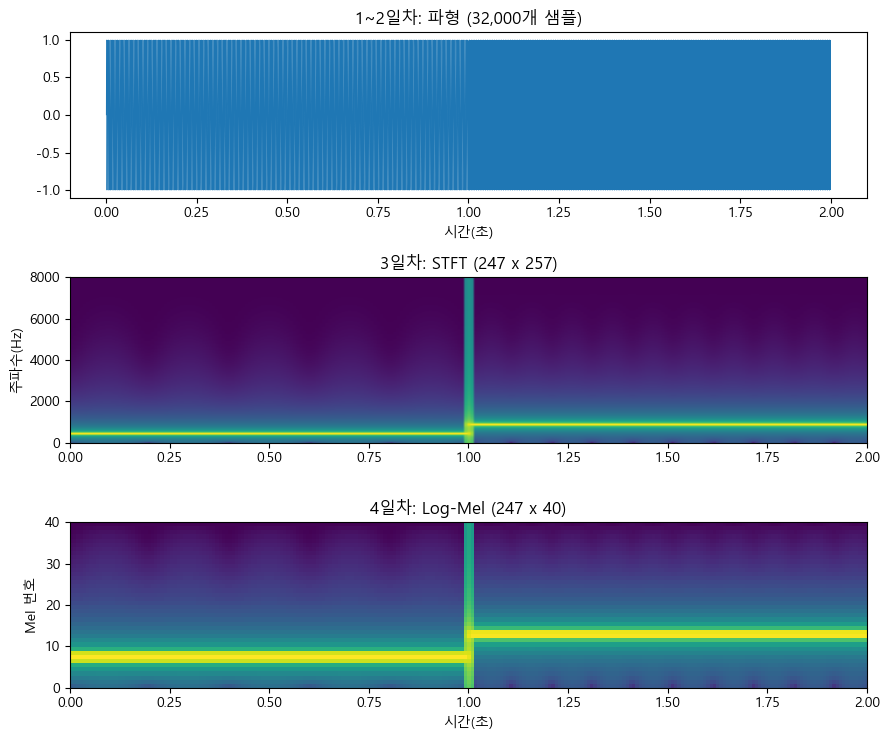

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5))

axes[0].plot(np.arange(len(signal)) / sr, signal, linewidth=0.3)
axes[0].set_title("1~2일차: 파형 (32,000개 샘플)")
axes[0].set_xlabel("시간(초)")

axes[1].imshow(np.log(power.T + 1e-10), origin="lower", aspect="auto",
               extent=[0, 2, 0, sr/2])
axes[1].set_title("3일차: STFT (247 x 257)")
axes[1].set_ylabel("주파수(Hz)")

axes[2].imshow(log_mel.T, origin="lower", aspect="auto", extent=[0, 2, 0, 40])
axes[2].set_title("4일차: Log-Mel (247 x 40)")
axes[2].set_xlabel("시간(초)"); axes[2].set_ylabel("Mel 번호")

plt.tight_layout(); plt.show()

Log-Mel 그림이 STFT보다 거칠어 보이는 것은 257칸을 40칸으로 묶었기 때문입니다. 대신 440Hz와 880Hz의 변화는 그대로 살아 있습니다.

1초 지점의 세로줄은 소리가 갑자기 바뀌면서 생기는 짧은 "딸깍" 소리입니다. 순간적인 잡음은 여러 주파수에 넓게 퍼져 나타납니다.

---
## 5~6일차 미리 보기

여기까지는 **소리를 숫자 특징으로 준비하는 과정**이었습니다. 이제 두 가지 질문이 남습니다.

1. **이 숫자 배열에 어떤 정답을 연결해야 할까요?**
2. **모델은 이 배열을 받아 무엇을 계산할까요?**

### 질문 1 · 입력과 정답을 짝지어야 합니다

모델은 **입력과 정답의 짝**을 많이 보면서 배웁니다. 단어 카드 앞면에 그림, 뒷면에 단어가 적혀 있는 것과 같습니다.

| 하고 싶은 일 | 입력 | 정답 |
|---|---|---|
| 명령어 분류 ("켜", "꺼") | Log-Mel 배열 | 단어 번호 하나 (예: 0 또는 1) |
| 받아쓰기 (STT) | Log-Mel 배열 | 글자들의 순서 (예: "안 녕 하 세 요") |

컴퓨터는 글자를 직접 다루지 못하므로, 정답도 **숫자로 바꿔서** 준비합니다.

In [13]:
# 명령어 분류: 단어마다 번호를 정해 둡니다.
label_map = {"켜": 0, "꺼": 1}
y_cmd = label_map["켜"]
print("정답 '켜' →", y_cmd)

# 받아쓰기: 글자마다 번호를 정해 두고 순서대로 바꿉니다.
text = "안녕하세요"
char_map = {ch: i for i, ch in enumerate(sorted(set(text)))}
y_stt = [char_map[ch] for ch in text]
print("정답 '안녕하세요' →", y_stt)

print("입력 길이(시간 프레임):", log_mel.shape[0], "/ 정답 길이(글자):", len(y_stt))

assert len(y_stt) == 5

정답 '켜' → 0
정답 '안녕하세요' → [2, 0, 4, 1, 3]
입력 길이(시간 프레임): 247 / 정답 길이(글자): 5


마지막 줄을 보면 **입력은 247칸인데 정답은 5글자**입니다. 어느 프레임이 어느 글자에 해당하는지 따로 표시되어 있지 않습니다.

이 길이 차이를 모델이 어떻게 다루는지가 다음 수업의 중요한 주제입니다.

### 함께 알아 둘 점 · 음성마다 길이가 다릅니다

2초짜리 음성은 247프레임, 3초짜리는 371프레임처럼 길이가 다릅니다. 여러 음성을 한 배치로 묶으려면 짧은 쪽에 빈 값을 채워 길이를 맞춥니다. 이것을 **패딩**이라고 합니다.

In [14]:
# 길이가 다른 음성 3개 (시간 프레임 수만 다르고 Mel 특징은 40개로 같음)
samples = [np.ones((247, 40)), np.ones((371, 40)), np.ones((120, 40))]
max_len = max(x.shape[0] for x in samples)

# 짧은 음성 뒤쪽을 0으로 채워 가장 긴 길이에 맞춥니다.
padded = np.zeros((len(samples), max_len, 40))
for i, x in enumerate(samples):
    padded[i, :len(x)] = x

lengths = [x.shape[0] for x in samples]   # 실제 길이는 따로 기억해 둡니다
print("배치 모양:", padded.shape)
print("실제 길이:", lengths)

assert padded.shape == (3, 371, 40)

배치 모양: (3, 371, 40)
실제 길이: [247, 371, 120]


채운 0은 진짜 소리가 아니므로, **실제 길이를 따로 기억해 두는 것**이 중요합니다.

### 질문 2 · 모델은 이 배열로 무엇을 할까요?

음성 모델의 구조는 크게 보면 다음과 같습니다.

```text
Log-Mel 배열 (1, 247, 40)
        ↓
   [ 인코더 ]   시간 순서대로 특징을 읽으며 "무슨 소리인지" 요약
        ↓
   [ 출력부 ]   단어 번호 또는 글자 순서로 바꿈
        ↓
   "켜"  또는  "안녕하세요"
```

5~6일차에는 이 상자 안에서 어떤 계산이 일어나는지, 그리고 준비한 입력·정답이 어떻게 사용되는지 살펴봅니다.

---
## 스스로 확인해 봅시다

다음 질문에 한 문장으로 답해 보세요. 답은 펼쳐서 확인합니다.

**Q1.** 16,000Hz로 녹음한 샘플 48,000개짜리 음성은 몇 초일까요?

<details><summary>정답 보기</summary>3초입니다. 48,000 ÷ 16,000 = 3</details>

**Q2.** 48,000Hz 음성을 쓰면서 `sr = 16000`으로 변수만 바꾸면 어떤 문제가 생길까요?

<details><summary>정답 보기</summary>배열이 그대로라서 실제보다 3배 길고 낮은 소리로 해석됩니다. 리샘플링으로 값을 다시 계산해야 합니다.</details>

**Q3.** FFT만으로 부족해서 STFT를 쓰는 이유는 무엇일까요?

<details><summary>정답 보기</summary>FFT는 어떤 주파수가 있는지만 알려 주고, 언제 나타났는지는 알려 주지 않기 때문입니다.</details>

**Q4.** `(1, 247, 40)`에서 각 숫자는 무엇을 뜻할까요?

<details><summary>정답 보기</summary>음성 1개, 시간 프레임 247개, 프레임마다 Mel 특징 40개입니다.</details>

**Q5.** Log-Mel 배열은 모델이 인식한 결과일까요?

<details><summary>정답 보기</summary>아닙니다. 모델에 넣기 위해 정리한 입력 특징일 뿐입니다. 정답을 연결하고 모델을 학습시키는 것은 5~6일차의 내용입니다.</details>